In [ ]:
# --- environment ---------------------------------------------------------------
# This notebook was written against the `scnome` conda environment.
#     conda env create -f env/scnome.yml && conda activate scnome
# See env/README.md for which notebook uses which environment.
.env_expected <- "scnome"
if (basename(dirname(dirname(R.home()))) != .env_expected)
  message("[env] expected the '", .env_expected, "' environment; R is from ",
          R.home(), ". See env/README.md.")

# --- repo paths: edit paths.yaml at the repository root, not this notebook ---
# Cached so that re-running this cell still works after it has setwd() away.
if (!exists(".repo_root")) {
  .r <- getwd()
  while (.r != "/" && !file.exists(file.path(.r, "paths.R"))) .r <- dirname(.r)
  stopifnot(file.exists(file.path(.r, "paths.R")))
  .repo_root <- .r
}
source(file.path(.repo_root, "paths.R"))

# ============================================================================
# LOAD ONLY -- RUN FIRST.  Loads every per-site bed ONCE into m_hcg / m_gch.
# Plotting/formatting lives in each plotting cell below (self-contained).
#   NOTE: genome-wide GCH is large (~200M sites); give the kernel tens of GB RAM.
# ============================================================================
suppressPackageStartupMessages(library(data.table))

PB_GCH <- file.path(WORK, "gm12878_cellline/pseudobulk_methylation/gm_pseudobulk_merged.GCH.6plus2.bed.gz")
BK_GCH <- file.path(TMP, "bulk_gm/pipeline/06b.methylation_merged/bulk_GM12878_merged.cyt.filtered.sort.GCH.6plus2.bed.gz")
PB_HCG <- file.path(WORK, "gm12878_cellline/pseudobulk_methylation/gm_pseudobulk_merged.HCG.6plus2.bed.gz")
BK_HCG <- file.path(TMP, "bulk_gm/pipeline/06b.methylation_merged/bulk_GM12878_merged.cyt.filtered.sort.HCG.6plus2.bed.gz")
FIGDIR <- file.path(WORK, "gm12878_cellline/figures")
MINCT  <- 10

# read 6plus2 bed: skip 'track' lines; cols chr,start,end,name,score,strand,rate%,cov
read6 <- function(p) {
  d <- fread(cmd = paste("zcat", p, "| grep -v '^track'"),
             header = FALSE, select = c(1,2,3,7,8),
             col.names = c("chr","start","end","rate","cov"))
  d[, .(chr, start, end, m = rate/100 * cov, cov)]
}
load_ctx <- function(pb_path, bk_path) {
  pb <- read6(pb_path); setnames(pb, c("chr","start","end","m_pb","cov_pb"))
  bk <- read6(bk_path); setnames(bk, c("chr","start","end","m_bk","cov_bk"))
  pb <- unique(pb, by = c("chr","start","end")); bk <- unique(bk, by = c("chr","start","end"))
  merge(pb, bk, by = c("chr","start","end"), all = TRUE)
}
m_hcg <- load_ctx(PB_HCG, BK_HCG)
m_gch <- load_ctx(PB_GCH, BK_GCH)
cat(sprintf("loaded: m_hcg = %s sites, m_gch = %s sites\n",
            format(nrow(m_hcg), big.mark=","), format(nrow(m_gch), big.mark=",")))


n = 9,779,549   Pearson r = 0.932   Spearman rho = 0.918


pdf 
  2

wrote /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/gm_sc_new/figures/newbulk_locus_HCG_methylation_minCT_10.pdf 


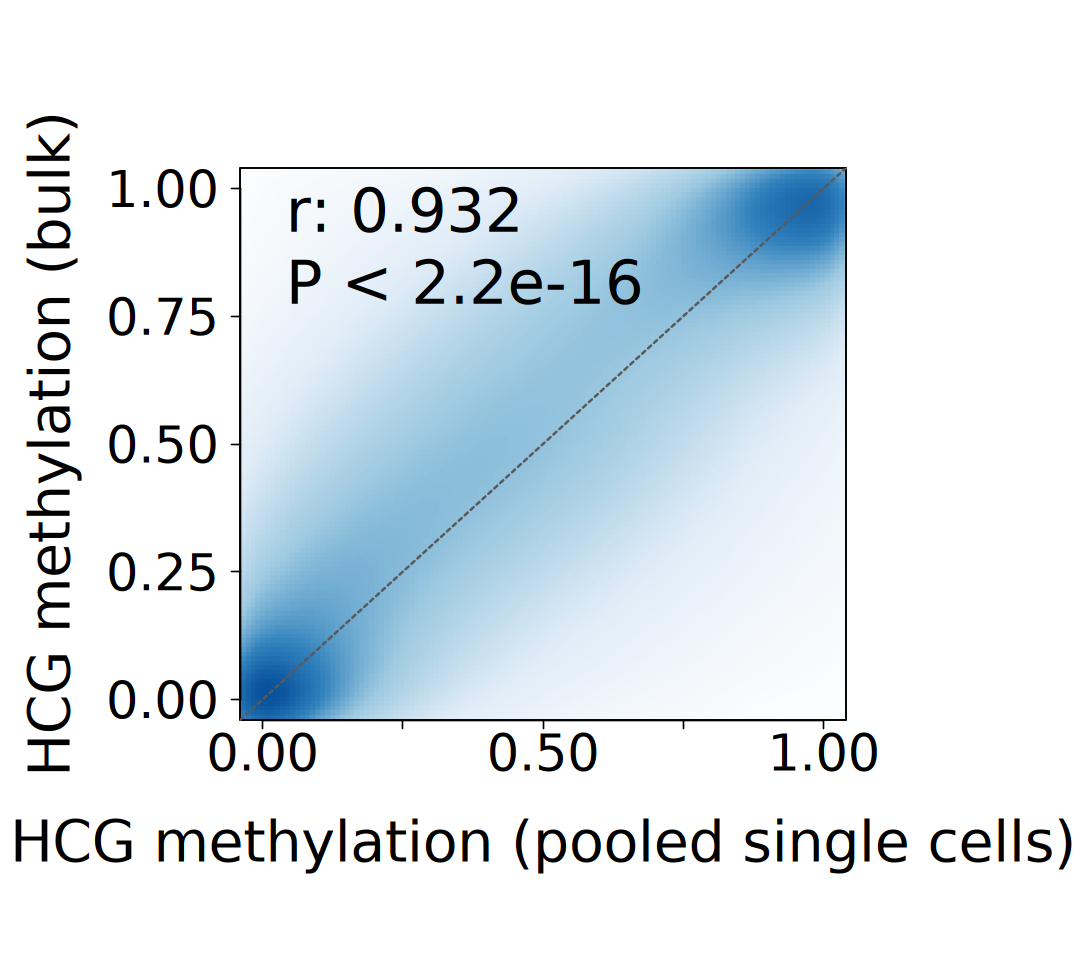

In [60]:
# Locus-level HCG (CpG methylation): pooled single cells vs from-scratch bulk, minCT >= 10.
stopifnot(exists("m_hcg"))
t <- MINCT
s <- m_hcg[cov_pb >= t & cov_bk >= t]
x <- s$m_pb / s$cov_pb
y <- s$m_bk / s$cov_bk
r_p <- cor(x, y)
r_s <- cor(x, y, method = "spearman")
cat(sprintf("n = %s   Pearson r = %.3f   Spearman rho = %.3f\n",
            format(nrow(s), big.mark = ","), r_p, r_s))

stat_choice <- "pearson"   # annotation: "pearson" or "spearman"
annot <- if (stat_choice == "spearman") sprintf("rho: %.3f\nP < 2.2e-16", r_s) else sprintf("r: %.3f\nP < 2.2e-16", r_p)

bpalette <- colorRampPalette(c("white", "#deebf7", "#9ecae1", "#3182bd", "#08519c"))
draw_one <- function() {
  par(mar = c(10, 10, 7, 10), mgp = c(6, 1.2, 0),
      cex.lab = 2.5, cex.axis = 2.5, family = "sans", tcl = -0.35, las = 1)
  smoothScatter(x, y, xlim = c(0, 1), ylim = c(0, 1), nrpoints = 0,
                xlab = "", ylab = "", main = "", colramp = bpalette, axes = FALSE)
  axis(1, at = seq(0, 1, by = 0.25), lwd = 1, mgp = c(3, 1.2, 0))
  axis(2, at = seq(0, 1, by = 0.25), lwd = 1, las = 1, mgp = c(3.5, 0.9, 0))
  mtext("HCG methylation (pooled single cells)", side = 1, line = 5.0, cex = 2.8)
  mtext("HCG methylation (bulk)", side = 2, line = 7,   cex = 2.8, las = 0)
  box(lwd = 1)
  abline(0, 1, lty = 2, lwd = 1.5, col = "grey35")
  text(0.02, 0.85, annot, pos = 4, cex = 3, font = 2)
}
out_pdf <- file.path(FIGDIR, "newbulk_locus_HCG_methylation_minCT_10.pdf")
fig_w <- 9.05; fig_h <- 8
pdf(out_pdf, width = fig_w, height = fig_h, useDingbats = FALSE, family = "Helvetica"); draw_one(); dev.off()
cat("wrote", out_pdf, "\n")
options(repr.plot.width = fig_w, repr.plot.height = fig_h); draw_one()


In [ ]:
# 250 kb-bin GCH accessibility -- DATA PREPARATION ONLY.
# Pools per-site GCH counts into 250 kb bins for both arms and builds `m`, which
# the quantile-normalized panel below consumes (it opens with stopifnot(exists("m"))).
# The un-normalized scatter that used to be plotted here was dropped: the published
# panel is the quantile-normalized one. See this folder's README for the raw vs
# quantile-normalized comparison.
stopifnot(exists("m_gch"))
BIN <- 250000
m <- m_gch[, .(m_pb = sum(m_pb, na.rm = TRUE), cov_pb = sum(cov_pb, na.rm = TRUE),
            m_bk = sum(m_bk, na.rm = TRUE), cov_bk = sum(cov_bk, na.rm = TRUE)),
        by = .(chr, bin = start %/% BIN)][cov_pb > 0 & cov_bk > 0][
        , .(chr, bin, pseudobulk = m_pb / cov_pb, bulk = m_bk / cov_bk)]
cat(sprintf("250 kb bins covered in both arms: n = %s\n", format(nrow(m), big.mark = ",")))


GCH 250kb QN   n = 11,670   Pearson r = 0.743   Spearman rho = 0.756


pdf 
  2

wrote /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/gm_sc_new/figures/newbulk_acc_250kb_GCH_quantileNorm.pdf 


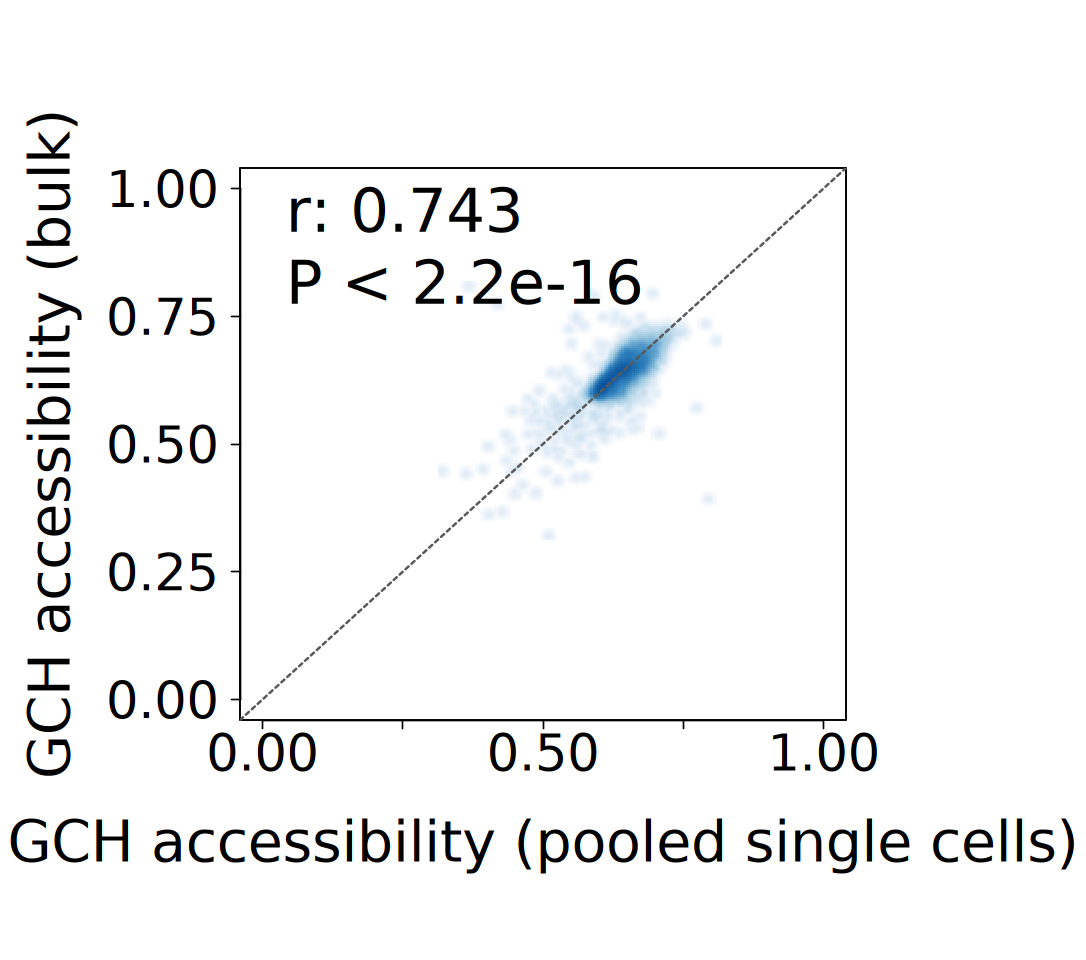

In [64]:
# 250kb GCH accessibility -- QUANTILE-NORMALIZED. Reuses `m` (250kb bins) from the
# previous cell. Same inline large-font format.
stopifnot(exists("m"))
quantile_normalize <- function(matrix_data) {
  n_rows <- nrow(matrix_data); n_cols <- ncol(matrix_data)
  max_non_na <- max(colSums(!is.na(matrix_data)))
  sorted_matrix <- matrix(NA_real_, nrow = max_non_na, ncol = n_cols)
  for (i in seq_len(n_cols)) { v <- matrix_data[, i]; v <- sort(v[!is.na(v)])
    sorted_matrix[seq_along(v), i] <- v }
  row_means <- rowMeans(sorted_matrix, na.rm = TRUE)
  out <- matrix(NA_real_, nrow = n_rows, ncol = n_cols, dimnames = dimnames(matrix_data))
  for (i in seq_len(n_cols)) { v <- matrix_data[, i]; na <- is.na(v)
    out[!na, i] <- row_means[rank(v[!na], ties.method = "average")] }
  out
}
qn <- quantile_normalize(as.matrix(as.data.frame(m)[, c("pseudobulk", "bulk")]))
x <- qn[, 1]; y <- qn[, 2]
r_p <- cor(x, y, use = "complete.obs")
r_s <- cor(x, y, method = "spearman", use = "complete.obs")
cat(sprintf("GCH 250kb QN   n = %s   Pearson r = %.3f   Spearman rho = %.3f\n",
            format(length(x), big.mark = ","), r_p, r_s))

stat_choice <- "pearson"   # annotation: "pearson" or "spearman"
annot <- if (stat_choice == "spearman") sprintf("rho: %.3f\nP < 2.2e-16", r_s) else sprintf("r: %.3f\nP < 2.2e-16", r_p)

bpalette <- colorRampPalette(c("white", "#deebf7", "#9ecae1", "#3182bd", "#08519c"))
draw_one <- function() {
  par(mar = c(10, 10, 7, 10), mgp = c(6, 1.2, 0),
      cex.lab = 2.5, cex.axis = 2.5, family = "sans", tcl = -0.35, las = 1)
  smoothScatter(x, y, xlim = c(0, 1), ylim = c(0, 1), nrpoints = 0,
                xlab = "", ylab = "", main = "", colramp = bpalette, axes = FALSE)
  axis(1, at = seq(0, 1, by = 0.25), lwd = 1, mgp = c(3, 1.2, 0))
  axis(2, at = seq(0, 1, by = 0.25), lwd = 1, las = 1, mgp = c(3.5, 0.9, 0))
  mtext("GCH accessibility (pooled single cells)", side = 1, line = 5.0, cex = 2.8)
  mtext("GCH accessibility (bulk)",                side = 2, line = 7,   cex = 2.8, las = 0)
  box(lwd = 1)
  abline(0, 1, lty = 2, lwd = 1.5, col = "grey35")
  text(0.02, 0.85, annot, pos = 4, cex = 3, font = 2)
}
out_pdf <- file.path(FIGDIR, "newbulk_acc_250kb_GCH_quantileNorm.pdf")
fig_w <- 9.05; fig_h <- 8
pdf(out_pdf, width = fig_w, height = fig_h, useDingbats = FALSE, family = "Helvetica"); draw_one(); dev.off()
cat("wrote", out_pdf, "\n")
options(repr.plot.width = fig_w, repr.plot.height = fig_h); draw_one()
